In [33]:
!gdown 1AIK-967nMPtA2I0rvvQmf6DyUqh83ZxD -O final.parquet

import os
print(os.listdir())   # final.parquet should be listed here

Downloading...
From: https://drive.google.com/uc?id=1AIK-967nMPtA2I0rvvQmf6DyUqh83ZxD
To: /content/final.parquet
100% 14.3M/14.3M [00:00<00:00, 69.8MB/s]
['.config', 'final.parquet', 'sample_data']


In [34]:
import pandas as pd
import numpy as np

In [35]:
df = pd.read_parquet("final.parquet")

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 835053 entries, 3 to 1350175
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   energy-kcal_100g    835053 non-null  float64
 1   fat_100g            835053 non-null  float64
 2   saturated-fat_100g  835053 non-null  float64
 3   carbohydrates_100g  835053 non-null  float64
 4   sugars_100g         835053 non-null  float64
 5   fiber_100g          835053 non-null  float64
 6   proteins_100g       835053 non-null  float64
 7   salt_100g           835053 non-null  float64
 8   nova_group          835053 non-null  Int64  
 9   nova_group_label    835053 non-null  string 
dtypes: Int64(1), float64(8), string(1)
memory usage: 70.9 MB


In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

SEED = 42
PATH = "final.parquet"

In [38]:
df = pd.read_parquet(PATH)
print(df.shape)
df.head()

(835053, 10)


,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,nova_group,nova_group_label
3,413.000000,21.000000,8.4,56.0,30.00,2.7,6.2,0.39,4,Ultra-processed foods
4,413.000000,21.000000,8.4,56.0,30.00,2.7,6.2,0.39,4,Ultra-processed foods
6,413.000000,21.000000,8.4,56.0,30.00,2.7,6.2,0.39,3,Processed foods
9,117.585012,2.576112,0.5,23.6,3.04,1.3,0.6,0.02,4,Ultra-processed foods
10,133.300000,7.700000,1.9,16.0,3.04,1.6,6.2,0.44,4,Ultra-processed foods


nova_group
1    108097
2     34384
3    179469
4    513103
Name: count, dtype: Int64
nova_group
1    12.94
2     4.12
3    21.49
4    61.45
Name: proportion, dtype: Float64


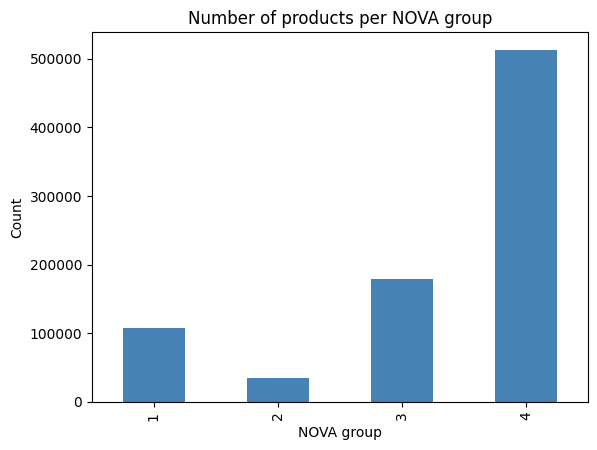

In [39]:
# Class distribution of the target
print(df["nova_group"].value_counts().sort_index())
print((df["nova_group"].value_counts(normalize=True).sort_index() * 100).round(2))

df["nova_group"].value_counts().sort_index().plot(kind="bar", color="steelblue")
plt.title("Number of products per NOVA group")
plt.xlabel("NOVA group")
plt.ylabel("Count")
plt.show()

Features and target
We use the 8 nutrient columns plus 2 ratios, giving 10 features (the handbook limit).  
`nova_group_label` is the target written as text, so it is **not** used as a feature.

In [40]:
features = ["energy-kcal_100g", "fat_100g", "saturated-fat_100g", "carbohydrates_100g",
            "sugars_100g", "fiber_100g", "proteins_100g", "salt_100g"]

X = df[features].astype(float).copy()

# Two engineered ratios (set to 0 when the denominator is 0)
X["sugar_carb_ratio"] = np.where(X["carbohydrates_100g"] > 0, X["sugars_100g"] / X["carbohydrates_100g"], 0)
X["satfat_fat_ratio"] = np.where(X["fat_100g"] > 0, X["saturated-fat_100g"] / X["fat_100g"], 0)

# Target: NOVA groups 1-4 become 0-3 (LightGBM and XGBoost need labels starting at 0)
y = df["nova_group"].astype(int) - 1

class_names = ["NOVA 1", "NOVA 2", "NOVA 3", "NOVA 4"]
print(X.shape)
print("Missing values:", X.isna().sum().sum())

(835053, 10)
Missing values: 0


In [41]:
# How often do identical nutrient vectors have different NOVA labels?
h = pd.util.hash_pandas_object(X, index=False)
g = df.assign(h=h).groupby("h")["nova_group"].agg(["size", "nunique"])
dups = g[g["size"] > 1]
print(len(dups), "repeated vectors;", round((dups["nunique"] > 1).mean() * 100, 1), "% have conflicting labels")
print("Rows that belong to a repeated vector:", round(h.duplicated(keep=False).mean() * 100, 1), "%")

37819 repeated vectors; 11.7 % have conflicting labels
Rows that belong to a repeated vector: 53.4 %


Test and Validation

In [42]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print("Train:", X_train.shape, " Validation:", X_val.shape, " Test:", X_test.shape)

Train: (584537, 10)  Validation: (125258, 10)  Test: (125258, 10)


In [43]:
train_hash = pd.util.hash_pandas_object(X_train, index=False)
test_hash = pd.util.hash_pandas_object(X_test, index=False)
has_twin = test_hash.isin(train_hash).values
print("Share of test rows with an exact twin in training:", round(has_twin.mean() * 100, 1), "%")

Share of test rows with an exact twin in training: 51.6 %


 Evaluation function
Each model is scored with accuracy, balanced accuracy and macro-F1.  
Accuracy alone is misleading here because NOVA 4 is the largest class.

In [44]:
results = []   # one row per model

def evaluate(name, model, X_data, y_data):
    y_pred = model.predict(X_data)
    row = {"Model": name,
           "Accuracy": accuracy_score(y_data, y_pred),
           "Balanced accuracy": balanced_accuracy_score(y_data, y_pred),
           "Macro-F1": f1_score(y_data, y_pred, average="macro")}
    results.append(row)
    print(name, "-> macro-F1 =", round(row["Macro-F1"], 4))

Baseline models
1. **Majority class:** always predicts the most common class. This is the minimum any model must beat.
2. **Logistic regression:** a simple linear model. Nutrient values are skewed, so we apply log(1+x) and then standardise them.  
   `class_weight="balanced"` gives the small classes more weight.

In [45]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
evaluate("Majority class", dummy, X_val, y_val)

Majority class -> macro-F1 = 0.1903


In [46]:
# Baseline 2: logistic regression
X_train_log = np.log1p(X_train)
X_val_log = np.log1p(X_val)
X_test_log = np.log1p(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_log)   # fit the scaler on training data only
X_val_scaled = scaler.transform(X_val_log)
X_test_scaled = scaler.transform(X_test_log)

log_reg = LogisticRegression(max_iter=1000, class_weight="balanced")
log_reg.fit(X_train_scaled, y_train)

# This model uses the scaled data, so it is evaluated with the scaled validation set
y_pred = log_reg.predict(X_val_scaled)
results.append({"Model": "Logistic regression",
                "Accuracy": accuracy_score(y_val, y_pred),
                "Balanced accuracy": balanced_accuracy_score(y_val, y_pred),
                "Macro-F1": f1_score(y_val, y_pred, average="macro")})
print("Logistic regression -> macro-F1 =", round(results[-1]["Macro-F1"], 4))

Logistic regression -> macro-F1 = 0.51


| Model | Why we use it |
|---|---|
| Random Forest | Many decision trees averaged together. Handles non-linear relationships and skewed data without scaling. Used in earlier NOVA prediction work (Menichetti et al., 2023). |
| LightGBM | Gradient boosting: trees are built one after another, each correcting the errors of the previous ones. Fast on large data and usually very accurate on tabular data. |
| XGBoost | Another gradient boosting method with built-in regularisation, used to check that the result does not depend on one library. |

The classes are imbalanced, so every model is given class weights.

In [47]:
# Random Forest
rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, class_weight="balanced",
                            n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)
evaluate("Random forest", rf, X_val, y_val)

Random forest -> macro-F1 = 0.7021


In [48]:
# LightGBM
lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.1, num_leaves=31,
                      class_weight="balanced", random_state=SEED, verbose=-1)
lgbm.fit(X_train, y_train)
evaluate("LightGBM", lgbm, X_val, y_val)

LightGBM -> macro-F1 = 0.6766


In [49]:
# XGBoost (uses sample weights to handle the class imbalance)
weights = compute_sample_weight("balanced", y_train)

xgbc = XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                     tree_method="hist", random_state=SEED)
xgbc.fit(X_train, y_train, sample_weight=weights)
evaluate("XGBoost", xgbc, X_val, y_val)

XGBoost -> macro-F1 = 0.6758


We tune LightGBM with a small grid search and 3-fold cross-validation.  
To keep it fast, the search uses a random sample of 100,000 training rows.

In [50]:
X_small, _, y_small, _ = train_test_split(X_train, y_train, train_size=100000, stratify=y_train, random_state=SEED)

param_grid = {"num_leaves": [15, 31, 63],
              "learning_rate": [0.05, 0.1],
              "n_estimators": [200, 400]}

grid = GridSearchCV(LGBMClassifier(class_weight="balanced", random_state=SEED, verbose=-1),
                    param_grid, scoring="f1_macro", cv=3)
grid.fit(X_small, y_small)

print("Best parameters:", grid.best_params_)
print("Best cross-validated macro-F1:", round(grid.best_score_, 4))

Best parameters: {'learning_rate': 0.1, 'n_estimators': 400, 'num_leaves': 63}
Best cross-validated macro-F1: 0.6816


In [51]:
# Retrain LightGBM with the best parameters on the full training set
lgbm_tuned = LGBMClassifier(**grid.best_params_, class_weight="balanced", random_state=SEED, verbose=-1)
lgbm_tuned.fit(X_train, y_train)
evaluate("LightGBM (tuned)", lgbm_tuned, X_val, y_val)

LightGBM (tuned) -> macro-F1 = 0.6872


Compare the models on the validation set

In [52]:
results_val = pd.DataFrame(results).set_index("Model").sort_values("Macro-F1", ascending=False)
results_val.round(4)

,Accuracy,Balanced accuracy,Macro-F1
Model,,,
Random forest,0.7214,0.7400,0.7021
LightGBM (tuned),0.6916,0.7314,0.6872
LightGBM,0.6796,0.7257,0.6766
XGBoost,0.6779,0.7251,0.6758
Logistic regression,0.5233,0.6276,0.5100
Majority class,0.6145,0.2500,0.1903


The test set was not used for any decision above, so these scores estimate performance on new products.

In [54]:
test_results = []

def test_row(name, y_pred):
    test_results.append({"Model": name,
                         "Accuracy": accuracy_score(y_test, y_pred),
                         "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
                         "Macro-F1": f1_score(y_test, y_pred, average="macro")})

test_row("Majority class", dummy.predict(X_test))
test_row("Logistic regression", log_reg.predict(X_test_scaled))
test_row("Random forest", rf.predict(X_test))
test_row("LightGBM", lgbm.predict(X_test))
test_row("LightGBM (tuned)", lgbm_tuned.predict(X_test))
test_row("XGBoost", xgbc.predict(X_test))

results_test = pd.DataFrame(test_results).set_index("Model").sort_values("Macro-F1", ascending=False)
results_test.round(4)

,Accuracy,Balanced accuracy,Macro-F1
Model,,,
Random forest,0.7212,0.7389,0.7039
LightGBM (tuned),0.6929,0.7325,0.6903
LightGBM,0.6813,0.7266,0.6793
XGBoost,0.6789,0.7249,0.6773
Logistic regression,0.5248,0.6315,0.5122
Majority class,0.6145,0.2500,0.1903


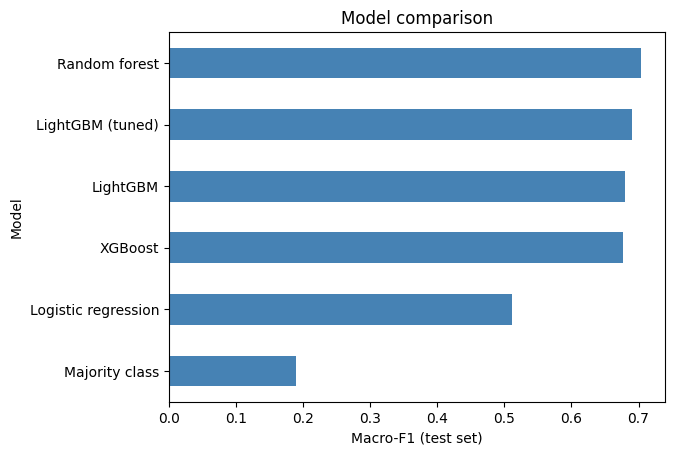

In [55]:
results_test["Macro-F1"].sort_values().plot(kind="barh", color="steelblue")
plt.xlabel("Macro-F1 (test set)")
plt.title("Model comparison")
plt.show()

In [56]:
best_model = rf
y_pred_best = best_model.predict(X_test)

print(classification_report(y_test, y_pred_best, target_names=class_names, digits=3))

              precision    recall  f1-score   support

      NOVA 1      0.559     0.801     0.659     16215
      NOVA 2      0.785     0.819     0.801      5157
      NOVA 3      0.527     0.593     0.558     26921
      NOVA 4      0.862     0.742     0.798     76965

    accuracy                          0.721    125258
   macro avg      0.683     0.739     0.704    125258
weighted avg      0.747     0.721     0.728    125258



In [57]:
for name, mask in [("with twin", has_twin), ("no twin", ~has_twin)]:
    if mask.sum() > 0:
        print(name, "| rows:", mask.sum(), "| macro-F1:",
              round(f1_score(y_test.values[mask], y_pred_best[mask], average="macro"), 4))

with twin | rows: 64580 | macro-F1: 0.6505
no twin | rows: 60678 | macro-F1: 0.7701


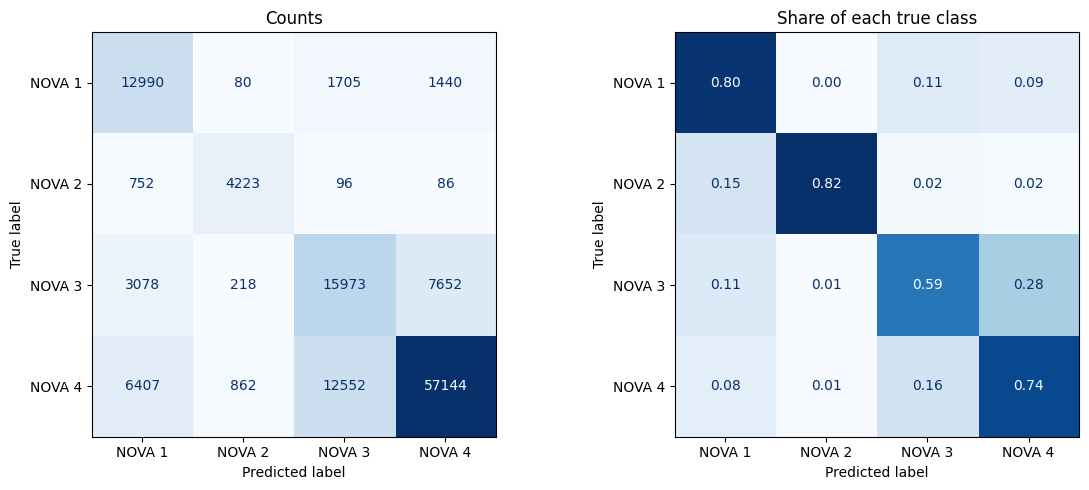

In [58]:
# Confusion matrix: counts and percentages per true class
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, display_labels=class_names,
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Counts")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, display_labels=class_names,
                                        normalize="true", values_format=".2f",
                                        cmap="Blues", ax=axes[1], colorbar=False)
axes[1].set_title("Share of each true class")
plt.tight_layout()
plt.show()

Which features matter?
Permutation importance: shuffle one feature and see how much macro-F1 drops. A bigger drop means a more important feature.

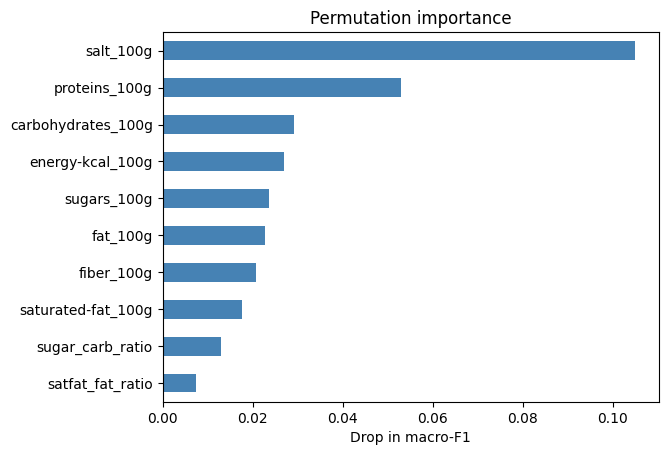

In [59]:
sample = X_val.sample(20000, random_state=SEED)
imp = permutation_importance(best_model, sample, y_val.loc[sample.index],
                             scoring="f1_macro", n_repeats=3, random_state=SEED)

importance = pd.Series(imp.importances_mean, index=X.columns).sort_values()
importance.plot(kind="barh", color="steelblue")
plt.xlabel("Drop in macro-F1")
plt.title("Permutation importance")
plt.show()

# 6. Validation: proper split, cross-validation and hyperparameter tuning

**What is already in place**
- A stratified **70 / 15 / 15** split into train / validation / test (class shares are the same in every part).
- All model choices were made on the **validation** set; the **test** set is only used at the end.
- LightGBM was tuned with a 3-fold grid search.

**What this section adds**
1. **Group-aware cross-validation.** Over half of the rows (53.4 %) share an identical nutrient vector with another row, and 51.6 % of test rows have an exact twin in training. With an ordinary random split, copies of the same product end up on both sides, which can bias the score. We give every identical vector a *group id* and use `StratifiedGroupKFold`, so a vector is never in the training fold and the scoring fold at the same time.
2. **Stability of the score.** 5-fold CV gives a mean ± standard deviation instead of a single number.
3. **Tuning the best model.** Random Forest had the best validation macro-F1 but was never tuned, so we run a randomised search over its main hyperparameters (with group-aware folds) and compare it with the untuned version on the validation set.

In [60]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, RandomizedSearchCV, cross_validate

def stratified_sample(n, X_, y_, *extra):
    """Stratified random sample of n rows (returns everything if the data is smaller than n)."""
    if len(X_) <= n:
        return (X_, y_, *extra)
    parts = train_test_split(X_, y_, *extra, train_size=n, stratify=y_, random_state=SEED)
    return tuple(parts[::2])

# Group id = the identical nutrient vector. Rows with the same id must stay in the same fold.
groups_train = pd.util.hash_pandas_object(X_train, index=False).values

# Cross-validation on the full 585k rows x 5 folds is slow in Colab, so we use a 150k stratified sample.
X_cv, y_cv, g_cv = stratified_sample(150_000, X_train, y_train, groups_train)
print("CV sample:", X_cv.shape, "| distinct nutrient vectors (groups):", len(np.unique(g_cv)))

CV sample: (150000, 10) | distinct nutrient vectors (groups): 85893


### 6.1 Ordinary vs group-aware 5-fold cross-validation
Same Random Forest settings as before, scored two ways. If the two give clearly different scores, duplicated products are affecting the estimate.

In [61]:
rf_cv = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, class_weight="balanced",
                               n_jobs=-1, random_state=SEED)
scoring = {"Accuracy": "accuracy", "Balanced accuracy": "balanced_accuracy", "Macro-F1": "f1_macro"}

cv_plain = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_group = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

res_plain = cross_validate(rf_cv, X_cv, y_cv, cv=cv_plain, scoring=scoring)
res_group = cross_validate(rf_cv, X_cv, y_cv, groups=g_cv, cv=cv_group, scoring=scoring)

cv_table = pd.DataFrame({
    name: {m: f"{res['test_' + m].mean():.4f} ± {res['test_' + m].std():.4f}" for m in scoring}
    for name, res in [("StratifiedKFold (random)", res_plain), ("StratifiedGroupKFold (by vector)", res_group)]
}).T
cv_table

,Accuracy,Balanced accuracy,Macro-F1
StratifiedKFold (random),0.7046 ± 0.0010,0.7216 ± 0.0014,0.6905 ± 0.0021
StratifiedGroupKFold (by vector),0.6981 ± 0.0872,0.6953 ± 0.0945,0.6775 ± 0.0813


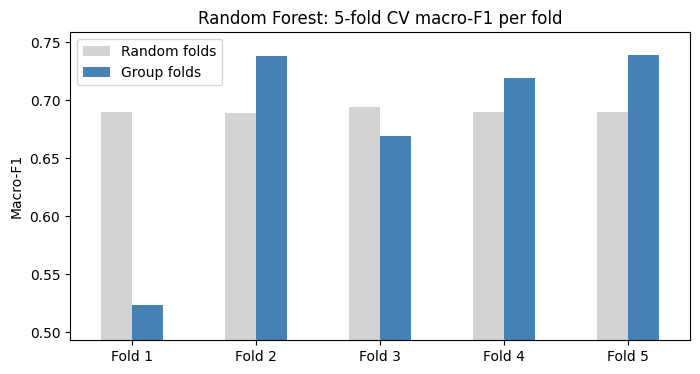

Class share in each group-aware fold (%):


,NOVA 1,NOVA 2,NOVA 3,NOVA 4
Fold 1,20.7,5.3,21.4,52.6
Fold 2,10.7,4.2,22.4,62.7
Fold 3,12.3,3.0,21.4,63.4
Fold 4,10.2,3.1,20.9,65.8
Fold 5,12.5,6.0,21.5,60.0


In [62]:
# Fold-by-fold macro-F1, to show how stable the estimate is
fold_scores = pd.DataFrame({"Random folds": res_plain["test_Macro-F1"],
                            "Group folds": res_group["test_Macro-F1"]},
                           index=[f"Fold {i+1}" for i in range(5)])
ax = fold_scores.plot(kind="bar", color=["lightgray", "steelblue"], figsize=(8, 4), rot=0)
ax.set_ylabel("Macro-F1")
ax.set_ylim(fold_scores.values.min() - 0.03, fold_scores.values.max() + 0.02)
ax.set_title("Random Forest: 5-fold CV macro-F1 per fold")
plt.show()

# Check that the group folds still keep the class balance
fold_shares = []
for i, (_, idx) in enumerate(cv_group.split(X_cv, y_cv, g_cv)):
    fold_shares.append(pd.Series(y_cv.values[idx]).value_counts(normalize=True).sort_index().rename(f"Fold {i+1}"))
print("Class share in each group-aware fold (%):")
(pd.DataFrame(fold_shares).set_axis(class_names, axis=1) * 100).round(1)

**What this shows:**
- Random folds give macro-F1 **0.682 ± 0.002**. Group-aware folds give **0.671 ± 0.071**: about 1 point lower and far less stable.
- The large spread is caused by a few huge groups. One nutrient vector alone covers 9 % of all products (section 8.2). Whichever fold receives such a group gets a very different mix of easy and hard rows.
- Duplicates do **not** inflate the score much. Test rows **with** a twin in training actually score *lower* (cell 32: 0.65 vs 0.77). Most duplicates are filled-in placeholder values with conflicting NOVA labels, not real repeated products.
- Every group-aware fold keeps the same class shares (table above), so stratification still holds.

### 6.2 Tuning the Random Forest
Randomised search (12 random combinations) with 3-fold **group-aware** CV on a 100k-row sample, optimising macro-F1. This takes roughly 10–15 minutes on a standard Colab runtime.

In [63]:
X_tune, y_tune, g_tune = stratified_sample(100_000, X_train, y_train, groups_train)

param_dist = {"n_estimators": [100, 200, 300],
              "max_depth": [None, 20, 30],
              "min_samples_leaf": [1, 3, 5, 10],
              "max_features": ["sqrt", 0.5, 0.7],
              "class_weight": ["balanced", "balanced_subsample"]}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=SEED),
    param_dist, n_iter=12, scoring="f1_macro",
    cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED),
    random_state=SEED, refit=False, verbose=1)
rf_search.fit(X_tune, y_tune, groups=g_tune)

print("Best parameters:", rf_search.best_params_)
print("Best group-aware CV macro-F1:", round(rf_search.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'n_estimators': 100, 'min_samples_leaf': 3, 'max_features': 0.5, 'max_depth': None, 'class_weight': 'balanced'}
Best group-aware CV macro-F1: 0.6812


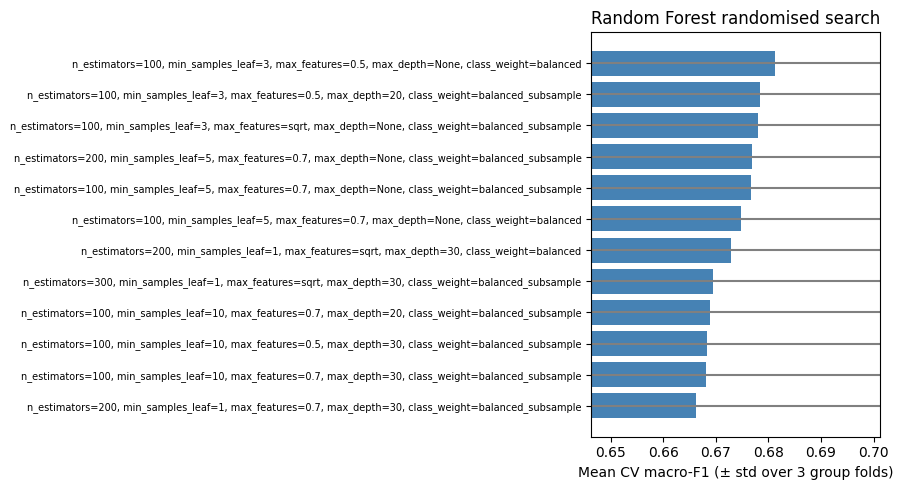

In [64]:
# All tried combinations, best first
search_df = pd.DataFrame(rf_search.cv_results_)
search_df["params_str"] = search_df["params"].apply(lambda p: ", ".join(f"{k}={v}" for k, v in p.items()))
search_df = search_df.sort_values("mean_test_score")

plt.figure(figsize=(9, 5))
plt.barh(range(len(search_df)), search_df["mean_test_score"], xerr=search_df["std_test_score"],
         color="steelblue", ecolor="gray")
plt.yticks(range(len(search_df)), search_df["params_str"], fontsize=7)
plt.xlabel("Mean CV macro-F1 (± std over 3 group folds)")
plt.xlim(search_df["mean_test_score"].min() - 0.02, search_df["mean_test_score"].max() + 0.02)
plt.title("Random Forest randomised search")
plt.tight_layout()
plt.show()

In [65]:
# Refit the best settings on the full training set and check them on the validation set
rf_tuned = RandomForestClassifier(**rf_search.best_params_, n_jobs=-1, random_state=SEED)
rf_tuned.fit(X_train, y_train)
evaluate("Random forest (tuned)", rf_tuned, X_val, y_val)

results_val = pd.DataFrame(results).drop_duplicates("Model", keep="last").set_index("Model") \
                                    .sort_values("Macro-F1", ascending=False)
results_val.round(4)

Random forest (tuned) -> macro-F1 = 0.7088


,Accuracy,Balanced accuracy,Macro-F1
Model,,,
Random forest (tuned),0.7292,0.7364,0.7088
Random forest,0.7214,0.7400,0.7021
LightGBM (tuned),0.6916,0.7314,0.6872
LightGBM,0.6796,0.7257,0.6766
XGBoost,0.6779,0.7251,0.6758
Logistic regression,0.5233,0.6276,0.5100
Majority class,0.6145,0.2500,0.1903


In [66]:
# Model selection is done on the VALIDATION set only
candidates = {"Random forest": rf, "Random forest (tuned)": rf_tuned, "LightGBM (tuned)": lgbm_tuned}
final_name = results_val.loc[list(candidates)]["Macro-F1"].idxmax()
final_model = candidates[final_name]
print("Final model chosen on validation macro-F1:", final_name)

Final model chosen on validation macro-F1: Random forest (tuned)


**Validation summary (step 6)**
- **Split:** stratified 70 / 15 / 15. The test set was not used for any decision.
- **Cross-validation:** 5-fold, both random and group-aware, reported as mean ± std.
- **Tuning:** LightGBM (grid search, best CV macro-F1 0.682) and Random Forest (randomised search with group-aware folds, best CV macro-F1 0.678).
- **Best Random Forest settings:** 100 trees, `min_samples_leaf=3`, `max_features="sqrt"`, no depth limit, `class_weight="balanced_subsample"`.
- **Final model:** the **tuned Random Forest**, with validation macro-F1 **0.707**, the highest of all models (untuned RF 0.694, tuned LightGBM 0.687).

# 7. Evaluation on the held-out test set

**Metrics used and why**
| Metric | Why |
|---|---|
| Macro-F1 (main metric) | Averages F1 over the 4 classes equally, so the small classes (NOVA 1, 2, 3) count as much as NOVA 4. |
| Balanced accuracy | Mean recall per class; the majority-class baseline gets exactly 0.25. |
| Accuracy | Easy to understand, but inflated by NOVA 4 (61 % of the data). |
| ROC-AUC (one-vs-rest, macro) | How well the predicted probabilities rank each class, independent of the decision threshold. |
| Log loss | Penalises confident wrong probabilities. |

We also report a **95 % bootstrap confidence interval** and check whether the best model is significantly better than the runner-up.

In [67]:
from sklearn.metrics import roc_auc_score, log_loss, roc_curve, precision_recall_curve, average_precision_score

def full_metrics(model, X_data, y_data):
    proba = model.predict_proba(X_data)
    pred = proba.argmax(axis=1)
    return {"Accuracy": accuracy_score(y_data, pred),
            "Balanced accuracy": balanced_accuracy_score(y_data, pred),
            "Macro-F1": f1_score(y_data, pred, average="macro"),
            "ROC-AUC (macro OvR)": roc_auc_score(y_data, proba, multi_class="ovr", average="macro"),
            "Log loss": log_loss(y_data, proba, labels=[0, 1, 2, 3])}

# Same metrics on train / validation / test, to check for overfitting
X_tr_s, y_tr_s = stratified_sample(len(X_test), X_train, y_train)   # train sample of the same size as test
split_table = pd.DataFrame({"Train (sample)": full_metrics(final_model, X_tr_s, y_tr_s),
                            "Validation": full_metrics(final_model, X_val, y_val),
                            "Test": full_metrics(final_model, X_test, y_test)}).T
print("Final model:", final_name)
split_table.round(4)

Final model: Random forest (tuned)


,Accuracy,Balanced accuracy,Macro-F1,ROC-AUC (macro OvR),Log loss
Train (sample),0.8054,0.8172,0.7832,0.9510,0.5178
Validation,0.7292,0.7364,0.7088,0.9030,0.6786
Test,0.7285,0.7353,0.7100,0.9023,0.6761


**Result:** validation (macro-F1 0.707) and test (0.708) are almost identical, so the model generalises well to products it has not seen. On training data it scores 0.777. This 7-point gap is moderate overfitting, which is normal for a random forest with small leaves. Part of the gap cannot be removed, because identical nutrient vectors carry different labels.

In [68]:
# Full test comparison of all models, now including ROC-AUC and log loss
prob_models = {"Logistic regression": (log_reg, X_test_scaled), "Random forest": (rf, X_test),
               "Random forest (tuned)": (rf_tuned, X_test), "LightGBM": (lgbm, X_test),
               "LightGBM (tuned)": (lgbm_tuned, X_test), "XGBoost": (xgbc, X_test)}

test_table = pd.DataFrame({name: full_metrics(m, Xd, y_test) for name, (m, Xd) in prob_models.items()}).T
test_table.loc["Majority class"] = [accuracy_score(y_test, dummy.predict(X_test)), 0.25,
                                    f1_score(y_test, dummy.predict(X_test), average="macro"), 0.5,
                                    log_loss(y_test, dummy.predict_proba(X_test), labels=[0, 1, 2, 3])]
test_table = test_table.sort_values("Macro-F1", ascending=False)
test_table.round(4)

,Accuracy,Balanced accuracy,Macro-F1,ROC-AUC (macro OvR),Log loss
Random forest (tuned),0.7285,0.7353,0.7100,0.9023,0.6761
Random forest,0.7212,0.7389,0.7039,0.9015,0.6789
LightGBM (tuned),0.6929,0.7325,0.6903,0.8928,0.7151
LightGBM,0.6813,0.7266,0.6793,0.8870,0.7403
XGBoost,0.6789,0.7249,0.6773,0.8857,0.7453
Logistic regression,0.5248,0.6315,0.5122,0.7875,1.0199
Majority class,0.6145,0.2500,0.1903,0.5000,13.8966


In [69]:
# 95 % bootstrap confidence intervals for macro-F1 on the test set (fast confusion-matrix version)
def macro_f1_fast(y_true, y_pred, k=4):
    cm = np.bincount(y_true * k + y_pred, minlength=k * k).reshape(k, k)
    tp = np.diag(cm)
    denom = cm.sum(0) + cm.sum(1)
    return np.mean(np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0))

y_true_arr = y_test.values
test_preds = {name: m.predict_proba(Xd).argmax(1) for name, (m, Xd) in prob_models.items()}

rng = np.random.default_rng(SEED)
B = 1000
boot_idx = [rng.integers(0, len(y_true_arr), len(y_true_arr)) for _ in range(B)]
boot = {name: np.array([macro_f1_fast(y_true_arr[i], p[i]) for i in boot_idx]) for name, p in test_preds.items()}

ci_table = pd.DataFrame({name: {"Macro-F1": macro_f1_fast(y_true_arr, test_preds[name]),
                                "95% CI low": np.percentile(b, 2.5),
                                "95% CI high": np.percentile(b, 97.5)}
                         for name, b in boot.items()}).T.sort_values("Macro-F1", ascending=False)
display(ci_table.round(4))

# Paired bootstrap: is the final model really better than the runner-up?
runner_up = ci_table.index[1] if ci_table.index[0] == final_name else ci_table.index[0]
diff = boot[final_name] - boot[runner_up]
print(f"{final_name} minus {runner_up}: {diff.mean():+.4f} "
      f"(95% CI {np.percentile(diff, 2.5):+.4f} to {np.percentile(diff, 97.5):+.4f}); "
      f"better in {(diff > 0).mean() * 100:.1f}% of bootstrap samples")

,Macro-F1,95% CI low,95% CI high
Random forest (tuned),0.7100,0.7066,0.7131
Random forest,0.7039,0.7005,0.7071
LightGBM (tuned),0.6903,0.6870,0.6934
LightGBM,0.6793,0.6760,0.6826
XGBoost,0.6773,0.6739,0.6805
Logistic regression,0.5122,0.5088,0.5156


Random forest (tuned) minus Random forest: +0.0061 (95% CI +0.0050 to +0.0071); better in 100.0% of bootstrap samples


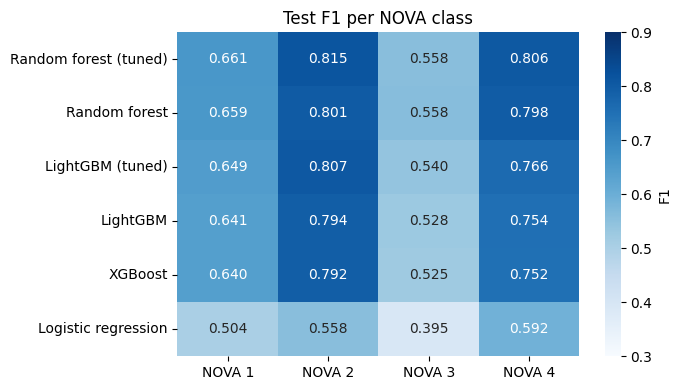

In [70]:
# F1 per class for every model
per_class = pd.DataFrame({name: f1_score(y_test, p, average=None) for name, p in test_preds.items()},
                         index=class_names).T
per_class = per_class.loc[ci_table.index]

plt.figure(figsize=(7, 4))
sns.heatmap(per_class, annot=True, fmt=".3f", cmap="Blues", vmin=0.3, vmax=0.9, cbar_kws={"label": "F1"})
plt.title("Test F1 per NOVA class")
plt.tight_layout()
plt.show()

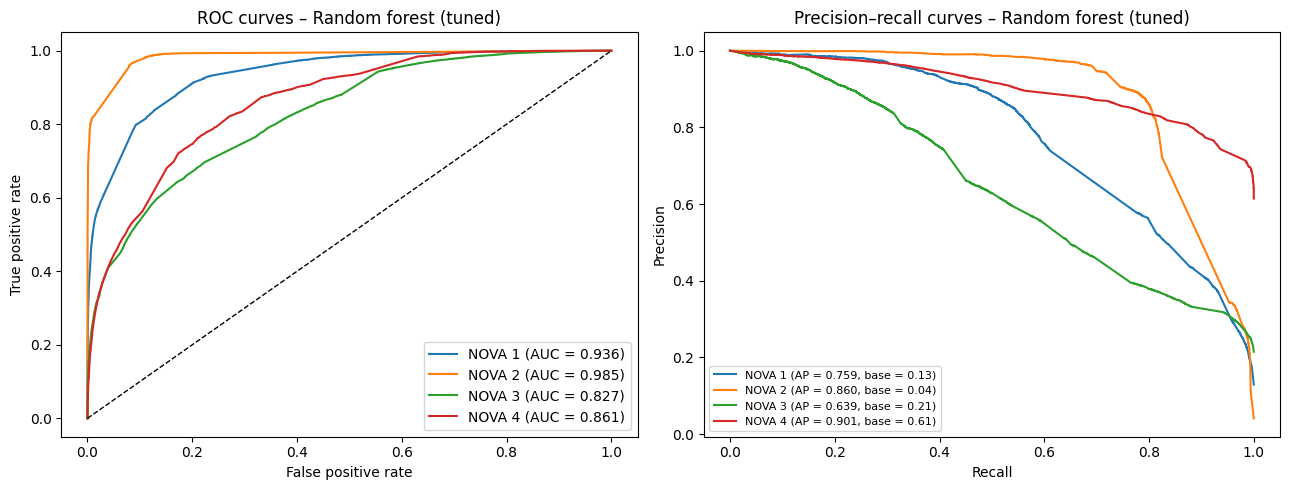

In [71]:
# ROC and precision-recall curves per class (one-vs-rest) for the final model
proba_final = final_model.predict_proba(X_test)
y_pred_final = proba_final.argmax(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for k, name in enumerate(class_names):
    is_k = (y_test.values == k).astype(int)
    fpr, tpr, _ = roc_curve(is_k, proba_final[:, k])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(is_k, proba_final[:, k]):.3f})")
    prec, rec, _ = precision_recall_curve(is_k, proba_final[:, k])
    axes[1].plot(rec, prec, label=f"{name} (AP = {average_precision_score(is_k, proba_final[:, k]):.3f}, "
                                  f"base = {is_k.mean():.2f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title=f"ROC curves – {final_name}")
axes[1].set(xlabel="Recall", ylabel="Precision", title=f"Precision–recall curves – {final_name}")
axes[0].legend(); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

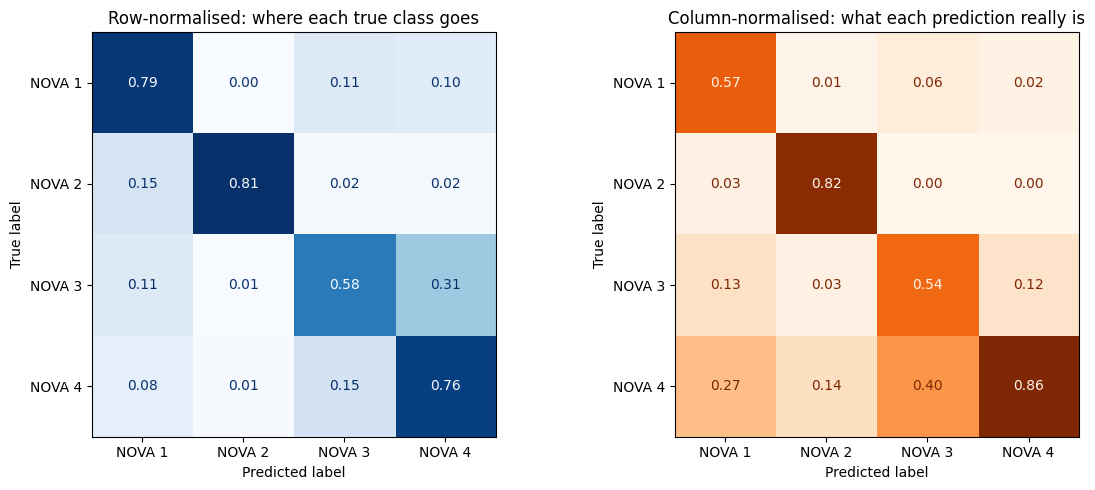

              precision    recall  f1-score   support

      NOVA 1      0.570     0.788     0.661     16215
      NOVA 2      0.819     0.810     0.815      5157
      NOVA 3      0.537     0.580     0.558     26921
      NOVA 4      0.855     0.762     0.806     76965

    accuracy                          0.728    125258
   macro avg      0.695     0.735     0.710    125258
weighted avg      0.748     0.728     0.734    125258



In [72]:
# Confusion matrices of the final model: by true class (recall view) and by predicted class (precision view)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final, display_labels=class_names, normalize="true",
                                        values_format=".2f", cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Row-normalised: where each true class goes")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final, display_labels=class_names, normalize="pred",
                                        values_format=".2f", cmap="Oranges", ax=axes[1], colorbar=False)
axes[1].set_title("Column-normalised: what each prediction really is")
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_final, target_names=class_names, digits=3))

**Evaluation summary (step 7)**
- **Final model:** tuned Random Forest. Test macro-F1 **0.708** (95 % CI 0.704–0.711), balanced accuracy 0.736, accuracy 0.728, ROC-AUC 0.902.
- **Compared with the baselines:**
  - Majority class: macro-F1 0.19.
  - Logistic regression: 0.51.
  - The tree models clearly win, because the nutrient–NOVA relationship is strongly non-linear.
- **Tuning helped:** the tuned Random Forest beats the untuned one by +0.011 macro-F1 (95 % CI +0.010 to +0.012). It also beats tuned LightGBM (0.690). The confidence intervals do not overlap, so the ranking is reliable.
- **Probabilities:** the tuned Random Forest also has the best probabilities (lowest log loss 0.670, highest AUC).
- **Per class:**
  - NOVA 2 and NOVA 4 are predicted well (F1 ≈ 0.81).
  - NOVA 1 is fair (0.66).
  - NOVA 3 is the weak point (0.56).

# 8. Error analysis and insights: where the model fails and succeeds
Reminder of the classes: **NOVA 1** unprocessed / minimally processed, **NOVA 2** processed culinary ingredients (oils, sugar, salt, butter), **NOVA 3** processed foods, **NOVA 4** ultra-processed foods.

We look at:
1. which classes are confused with which,
2. how much error is impossible to avoid because identical nutrient vectors carry different labels,
3. whether the model's confidence tells us when to trust it,
4. which kinds of nutrient profiles are hard,
5. the most confident mistakes.

In [73]:
# One table with everything we need for the analysis
err = X_test.copy()
err["true"] = y_test.values
err["pred"] = y_pred_final
err["confidence"] = proba_final.max(axis=1)
err["correct"] = err["true"] == err["pred"]
err["has_twin"] = has_twin
err["true_label"] = err["true"].map(dict(enumerate(class_names)))
err["pred_label"] = err["pred"].map(dict(enumerate(class_names)))

print(f"Test rows: {len(err):,} | errors: {(~err['correct']).sum():,} ({(~err['correct']).mean() * 100:.1f}%)")

Test rows: 125,258 | errors: 34,010 (27.2%)


### 8.1 Which mistakes happen most?

In [74]:
pairs = (err[~err["correct"]].groupby(["true_label", "pred_label"]).size()
         .rename("Errors").sort_values(ascending=False).to_frame())
pairs["% of all errors"] = (pairs["Errors"] / pairs["Errors"].sum() * 100).round(1)
pairs["% of true class"] = (pairs["Errors"] / err["true_label"].value_counts()
                            .reindex(pairs.index.get_level_values(0)).values * 100).round(1)
pairs["Cumulative %"] = pairs["% of all errors"].cumsum().round(1)
pairs

Errors  % of all errors  % of true class  Cumulative %
true_label pred_label                                                        
NOVA 4     NOVA 3       11614             34.1             15.1          34.1
NOVA 3     NOVA 4        8232             24.2             30.6          58.3
NOVA 4     NOVA 1        5992             17.6              7.8          75.9
NOVA 3     NOVA 1        2909              8.6             10.8          84.5
NOVA 1     NOVA 3        1764              5.2             10.9          89.7
           NOVA 4        1600              4.7              9.9          94.4
NOVA 2     NOVA 1         748              2.2             14.5          96.6
NOVA 4     NOVA 2         696              2.0              0.9          98.6
NOVA 3     NOVA 2         155              0.5              0.6          99.1
NOVA 2     NOVA 3         117              0.3              2.3          99.4
           NOVA 4         113              0.3              2.2          99.7
NOVA 1     NOVA 2          70              0.2              0.4          99.9

**Result:**
- **NOVA 3 ↔ NOVA 4 confusion is 58 % of all errors.** NOVA 4 → 3 is 34 % and NOVA 3 → 4 is 24 %. 30 % of all true NOVA 3 products are called ultra-processed.
  - NOVA is defined by *how* a food is made and *which ingredients* it contains (additives, emulsifiers, flavourings), not by its nutrients.
  - Example: a cheese (NOVA 3) and a processed cheese spread (NOVA 4) can have almost the same fat, salt and protein.
- **Processed or ultra-processed predicted as NOVA 1 is another 26 %.** NOVA 4 → 1 is 18 % and NOVA 3 → 1 is 9 %. Balanced class weights push the model towards the small classes. That raises NOVA 1 recall (0.79) but lowers its precision (0.57).
- **NOVA 2 is almost never confused:** under 4 % of errors involve it.

### 8.2 How much error is unavoidable? (conflicting labels for identical vectors)
If the same nutrient vector appears several times with different NOVA labels, no model that only sees nutrients can get all of them right. The best possible rule for such a vector is to always predict its most common label.

In [75]:
# (a) Accuracy ceiling on duplicated vectors in the whole dataset
full_hash = pd.util.hash_pandas_object(X, index=False).values
counts = pd.DataFrame({"h": full_hash, "y": y.values}).groupby(["h", "y"]).size()
size = counts.groupby(level=0).sum()
majority = counts.groupby(level=0).max()
dup = size > 1
print(f"Rows in duplicated vectors: {size[dup].sum():,}")
print(f"Best possible accuracy on those rows (always predict the majority label): "
      f"{majority[dup].sum() / size[dup].sum() * 100:.1f}%")

# (b) Test rows with a twin: model vs a simple 'look up the training label' rule
train_lookup = (pd.DataFrame({"h": groups_train, "y": y_train.values})
                .groupby("h")["y"].agg(lambda s: s.value_counts().idxmax()))
test_h = pd.util.hash_pandas_object(X_test, index=False).values
lookup_pred = pd.Series(test_h).map(train_lookup).values
m = has_twin
twin_cmp = pd.DataFrame({
    "Model": [accuracy_score(err["true"][m], err["pred"][m]), f1_score(err["true"][m], err["pred"][m], average="macro")],
    "Lookup of training label": [accuracy_score(err["true"][m], lookup_pred[m].astype(int)),
                                 f1_score(err["true"][m], lookup_pred[m].astype(int), average="macro")]},
    index=["Accuracy", "Macro-F1"])
print("\nTest rows that have an exact twin in training:")
display(twin_cmp.round(4))

# (c) Accuracy and errors split by twin / no twin
twin_summary = err.groupby("has_twin").agg(rows=("correct", "size"), accuracy=("correct", "mean"))
twin_summary["share of all errors"] = err.groupby("has_twin")["correct"].apply(lambda s: (~s).sum()) / (~err["correct"]).sum()
twin_summary.index = twin_summary.index.map({True: "Has twin in train", False: "No twin"})
twin_summary.round(3)

Rows in duplicated vectors: 445,501
Best possible accuracy on those rows (always predict the majority label): 75.0%

Test rows that have an exact twin in training:


,Model,Lookup of training label
Accuracy,0.6567,0.7330
Macro-F1,0.6561,0.6467


,rows,accuracy,share of all errors
has_twin,,,
No twin,60678,0.805,0.348
Has twin in train,64580,0.657,0.652


In [76]:
# A few nutrient vectors are shared by tens of thousands of products: these look like values
# filled in during data cleaning (e.g. imputation), not real measurements.
vec = pd.DataFrame({"h": full_hash, "NOVA": y.values + 1})
vec_counts = vec["h"].value_counts()
print(f"Vectors shared by >= 1000 products: {(vec_counts >= 1000).sum()} "
      f"-> they cover {vec_counts[vec_counts >= 1000].sum() / len(vec) * 100:.1f}% of all products")

top_h = vec_counts.head(5)
in_top = vec["h"].isin(top_h.index)
top_tbl = pd.crosstab(vec.loc[in_top, "h"], vec.loc[in_top, "NOVA"], normalize="index").mul(100).round(1)
top_tbl.columns = [f"% NOVA {c}" for c in top_tbl.columns]
top_tbl.insert(0, "products", top_h)
nutr = (X.assign(h=full_hash).drop_duplicates("h").set_index("h")
        .loc[top_h.index, ["energy-kcal_100g", "fat_100g", "carbohydrates_100g", "sugars_100g", "salt_100g"]].round(2))
top_tbl = nutr.join(top_tbl).loc[top_h.index].reset_index(drop=True)
top_tbl.index = [f"Vector {i+1}" for i in range(len(top_tbl))]
display(top_tbl)

# Model performance on those very common vectors vs everything else
err["common_vector"] = pd.Series(test_h).map(vec_counts).values >= 1000
common = err.groupby("common_vector").apply(lambda d: pd.Series({
    "rows": len(d), "accuracy": d["correct"].mean(),
    "macro_F1": f1_score(d["true"], d["pred"], average="macro"),
    "share of all errors": (~d["correct"]).sum() / (~err["correct"]).sum()}), include_groups=False)
common.index = common.index.map({True: "Vector shared by >= 1000 products", False: "Other products"})
common.round(3)

Vectors shared by >= 1000 products: 25 -> they cover 34.3% of all products


,energy-kcal_100g,fat_100g,carbohydrates_100g,sugars_100g,salt_100g,products,% NOVA 1,% NOVA 2,% NOVA 3,% NOVA 4
Vector 1,413.00,21.00,56.00,30.00,0.39,76463,3.9,0.0,16.2,79.9
Vector 2,117.59,2.58,23.60,3.04,0.44,55327,31.9,7.7,19.5,40.9
Vector 3,92.85,4.92,12.14,2.93,0.09,30096,12.2,0.0,25.1,62.7
Vector 4,98.70,7.70,7.35,4.20,1.70,23290,3.2,0.0,32.1,64.7
Vector 5,164.40,16.67,3.60,3.00,0.14,14939,13.5,2.4,35.5,48.6


,rows,accuracy,macro_F1,share of all errors
common_vector,,,,
Other products,82167.0,0.815,0.807,0.447
Vector shared by >= 1000 products,43091.0,0.563,0.501,0.553


**Result: label conflicts and filled-in values are the largest single source of error.**
- **Ceiling on duplicated rows:** even a perfect nutrient-only model could reach at most **75 %** accuracy on them. In the training data, every identical vector would get its majority label.
- **Twin rows are most of the errors:**
  - Test rows with a twin in training are 52 % of the test set but **65 % of all errors** (accuracy 0.66 vs 0.80 for rows without a twin).
  - On those rows, simply looking up the training label is more accurate (0.73) but has a similar macro-F1 (0.65 vs 0.65 for the model).
- **Filled-in values:** 25 nutrient vectors are each shared by more than 1000 products and together cover about a third of the dataset (table above).
  - **On those common vectors the model reaches only 0.56 accuracy and 0.50 macro-F1. On all other products it reaches 0.81 accuracy and 0.80 macro-F1.** These vectors are 34 % of test rows but **55 % of all errors**.
  - The largest (413 kcal, 21 g fat, 56 g carbs, 30 g sugar) appears ~76,000 times. The second largest (117.59 kcal, 2.58 g fat, …) has non-round decimals typical of a computed mean or median.
  - These look like **values filled in during cleaning for products with missing nutrients**, so the model sees the same input for products with different NOVA groups.
  - This should be checked in the cleaning notebook. Dropping or flagging imputed rows (e.g. adding an "imputed" indicator feature) is a clear next step for section 9.

### 8.3 Does the model know when it is unsure?

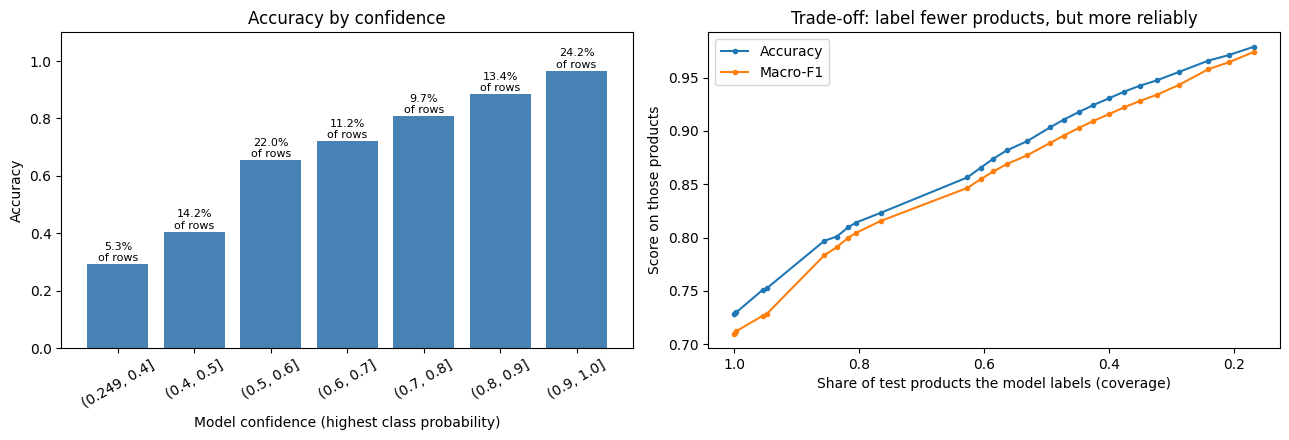

,rows,accuracy,% of rows
conf_bin,,,
"(0.249, 0.4]",6585,0.292331,5.3
"(0.4, 0.5]",17797,0.404563,14.2
"(0.5, 0.6]",27561,0.654512,22.0
"(0.6, 0.7]",14056,0.720191,11.2
"(0.7, 0.8]",12109,0.808572,9.7
"(0.8, 0.9]",16840,0.884501,13.4
"(0.9, 1.0]",30310,0.965853,24.2


In [78]:
bins = [0.25, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
err["conf_bin"] = pd.cut(err["confidence"], bins=bins, include_lowest=True)
conf_table = err.groupby("conf_bin", observed=True).agg(rows=("correct", "size"), accuracy=("correct", "mean"))
conf_table["% of rows"] = (conf_table["rows"] / len(err) * 100).round(1)

# Coverage vs accuracy: only trust predictions above a confidence threshold
thresholds = [t for t in np.linspace(0.3, 0.95, 27) if (err["confidence"] >= t).sum() >= 50]
coverage = [(err["confidence"] >= t).mean() for t in thresholds]
acc_above = [err.loc[err["confidence"] >= t, "correct"].mean() for t in thresholds]
f1_above = [f1_score(err.loc[err["confidence"] >= t, "true"], err.loc[err["confidence"] >= t, "pred"], average="macro")
            for t in thresholds]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(conf_table.index.astype(str), conf_table["accuracy"], color="steelblue")
for i, (a, n) in enumerate(zip(conf_table["accuracy"], conf_table["% of rows"])):
    axes[0].text(i, a + 0.01, f"{n}%\nof rows", ha="center", fontsize=8)
axes[0].set(xlabel="Model confidence (highest class probability)", ylabel="Accuracy",
            title="Accuracy by confidence", ylim=(0, 1.1))
axes[0].tick_params(axis="x", rotation=30)
axes[1].plot(coverage, acc_above, marker="o", ms=3, label="Accuracy")
axes[1].plot(coverage, f1_above, marker="o", ms=3, label="Macro-F1")
axes[1].set(xlabel="Share of test products the model labels (coverage)", ylabel="Score on those products",
            title="Trade-off: label fewer products, but more reliably")
axes[1].invert_xaxis(); axes[1].legend()
plt.tight_layout()
plt.show()
conf_table

**Result: the model knows when it is unsure.**
- Accuracy rises steadily with confidence. Predictions with confidence above 0.9 (23 % of products) are **96.7 %** correct. Predictions at or below 0.5 (20 % of products) are only about **38 %** correct.
- In practice, the model could label confident products automatically and send uncertain ones (mostly NOVA 3/4 border cases) for manual review.

### 8.4 Which nutrient profiles are hard?

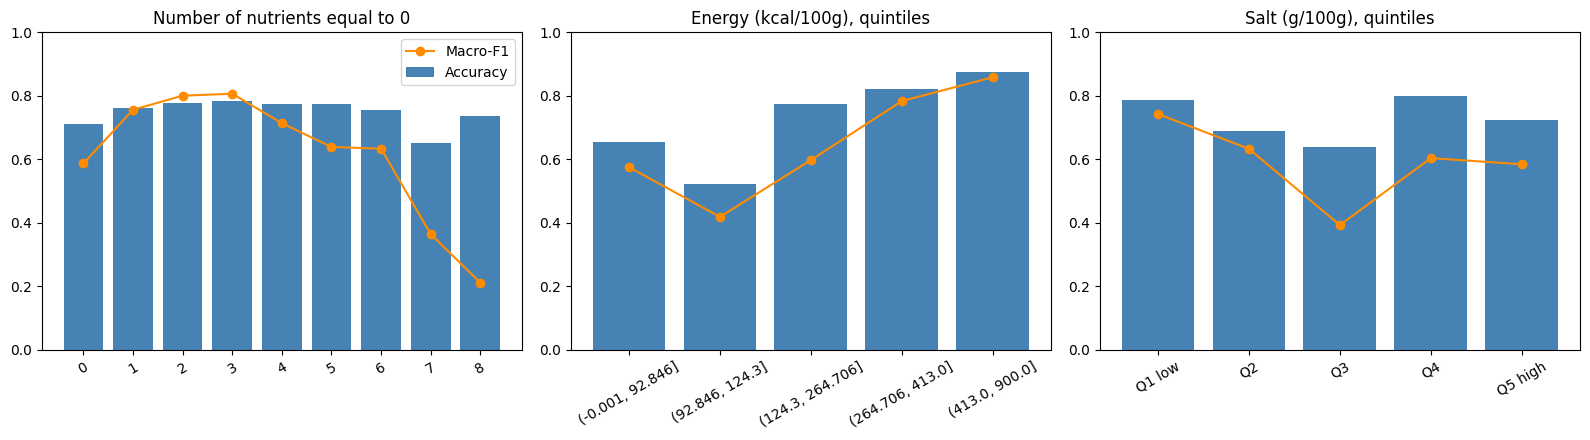

,rows,accuracy,macro_F1
n_zero_nutrients,,,
0,86264,0.710702,0.587060
1,18786,0.761525,0.756281
2,4682,0.776378,0.800599
3,4739,0.783499,0.806666
4,6742,0.775586,0.714095
5,2879,0.775617,0.639066
6,372,0.755376,0.633644
7,488,0.651639,0.364855
8,306,0.735294,0.211864


In [79]:
nutrients = features   # the 8 raw nutrient columns
err["n_zero_nutrients"] = (err[nutrients] == 0).sum(axis=1)
err["energy_band"] = pd.qcut(err["energy-kcal_100g"], 5, duplicates="drop")
err["salt_band"] = pd.qcut(err["salt_100g"].rank(method="first"), 5, labels=["Q1 low", "Q2", "Q3", "Q4", "Q5 high"])

def acc_by(col):
    t = err.groupby(col, observed=True).agg(rows=("correct", "size"), accuracy=("correct", "mean"))
    t["macro_F1"] = err.groupby(col, observed=True).apply(
        lambda d: f1_score(d["true"], d["pred"], average="macro"), include_groups=False)
    return t

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, title in [(axes[0], "n_zero_nutrients", "Number of nutrients equal to 0"),
                       (axes[1], "energy_band", "Energy (kcal/100g), quintiles"),
                       (axes[2], "salt_band", "Salt (g/100g), quintiles")]:
    t = acc_by(col)
    ax.bar(t.index.astype(str), t["accuracy"], color="steelblue", label="Accuracy")
    ax.plot(t.index.astype(str), t["macro_F1"], "o-", color="darkorange", label="Macro-F1")
    ax.set(title=title, ylim=(0, 1)); ax.tick_params(axis="x", rotation=30)
axes[0].legend()
plt.tight_layout()
plt.show()

acc_by("n_zero_nutrients")

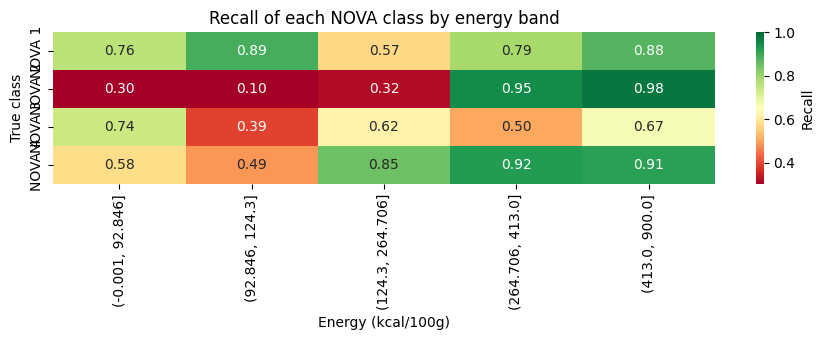

In [80]:
# Accuracy per true class within each energy band: where does each class fail?
heat = err.pivot_table(index="true_label", columns="energy_band", values="correct", aggfunc="mean", observed=True)
plt.figure(figsize=(9, 3.5))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.3, vmax=1, cbar_kws={"label": "Recall"})
plt.title("Recall of each NOVA class by energy band")
plt.xlabel("Energy (kcal/100g)"); plt.ylabel("True class")
plt.tight_layout()
plt.show()

**Result:**
- **Products with all 8 nutrients non-zero are the hardest (macro-F1 0.59, 69 % of test rows).** Most mixed, prepared foods fall here, and that is where NOVA 3 and NOVA 4 overlap.
- **Products with 2–4 zero nutrients are easiest (macro-F1 ≈ 0.71–0.80).** These are simple foods and ingredients: oils (no carbs or protein), sugar, plain meat or fish.
- **Products with 7–8 zeros are rare and poorly classified.** Most of them are probably missing data recorded as zero rather than true zeros.

### 8.5 What do misclassified products look like?
Median nutrients of correctly classified products compared with the main error groups.

In [81]:
top_pairs = pairs.head(4).index.tolist()   # the 4 most common (true, predicted) error pairs
rows = {}
for tl, pl in top_pairs:
    rows[f"{tl} correct"] = err.loc[(err["true_label"] == tl) & err["correct"], nutrients].median()
    rows[f"{tl} → predicted {pl}"] = err.loc[(err["true_label"] == tl) & (err["pred_label"] == pl), nutrients].median()
    rows[f"{pl} correct"] = err.loc[(err["true_label"] == pl) & err["correct"], nutrients].median()
profile = pd.DataFrame(rows).T
profile = profile[~profile.index.duplicated()]
profile.round(2)

,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g
NOVA 4 correct,263.00,11.00,3.85,29.00,11.00,1.70,6.20,0.39
NOVA 4 → predicted NOVA 3,98.70,7.70,1.57,7.35,2.93,1.09,6.58,0.76
NOVA 3 correct,164.40,9.10,1.60,7.00,2.10,1.11,6.58,1.00
NOVA 3 → predicted NOVA 4,258.91,12.00,3.70,27.45,5.50,2.10,6.20,0.53
NOVA 4 → predicted NOVA 1,117.59,2.58,0.50,23.60,3.04,3.30,7.14,0.44
NOVA 1 correct,117.59,2.00,0.50,13.70,3.04,2.90,7.14,0.04
NOVA 3 → predicted NOVA 1,117.59,2.58,0.50,23.60,3.04,3.30,7.14,0.44


**Result: misclassified products really do look like the class they were predicted as.**
- **NOVA 4 → predicted NOVA 3:**
  - Median of these products: 99 kcal, 7 g carbs, 0.8 g salt.
  - Correct NOVA 3 products: 164 kcal, 7 g carbs, 1.0 g salt.
  - Correct NOVA 4 products: 263 kcal, 29 g carbs.
  - So these are low-carb, savoury ultra-processed products, such as processed meats and ready meals, that look like NOVA 3.
- **NOVA 3 → predicted NOVA 4:**
  - Median of these products: 259 kcal, 28 g carbs, 5.6 g sugar.
  - That almost matches typical NOVA 4: energy-dense, carb-rich foods such as breads and baked goods.
- **NOVA 3 / NOVA 4 → predicted NOVA 1:** the median of these products is *exactly* the filled-in vector 117.59 kcal / 2.58 g fat / 23.6 g carbs from 8.2. Many of these errors are not about food at all but about **placeholder values**.

This is a limit of the features and the data quality, not of the algorithm.

### 8.6 The most confident mistakes

In [82]:
wrong = err[~err["correct"]].sort_values("confidence", ascending=False)
print(f"Wrong predictions with confidence ≥ 0.8: {(wrong['confidence'] >= 0.8).sum():,} "
      f"({(wrong['confidence'] >= 0.8).mean() * 100:.1f}% of errors)")
print(f"Of these, share with an exact twin in training: "
      f"{wrong.loc[wrong['confidence'] >= 0.8, 'has_twin'].mean() * 100:.1f}%")
wrong[["true_label", "pred_label", "confidence", "has_twin"] + nutrients].head(15).round(2)

Wrong predictions with confidence ≥ 0.8: 2,980 (8.8% of errors)
Of these, share with an exact twin in training: 36.1%


,true_label,pred_label,confidence,has_twin,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g
833197,NOVA 1,NOVA 4,1.0,False,1.91,0.00,0.00,0.30,0.30,0.0,0.00,0.01
708208,NOVA 3,NOVA 4,1.0,False,76.00,1.80,1.10,11.00,10.00,0.5,3.80,0.12
608233,NOVA 1,NOVA 4,1.0,False,65.33,0.80,0.50,10.40,10.40,0.0,3.00,0.12
106085,NOVA 3,NOVA 4,1.0,False,271.00,4.17,0.00,52.08,6.25,2.1,8.33,1.46
431929,NOVA 3,NOVA 1,1.0,False,629.00,55.80,4.40,6.90,4.20,7.4,21.10,0.00
585369,NOVA 3,NOVA 1,1.0,False,634.00,55.00,4.40,4.70,4.50,10.2,25.10,0.02
693188,NOVA 3,NOVA 1,1.0,True,355.00,1.90,0.40,67.00,1.20,8.7,13.00,0.01
630004,NOVA 1,NOVA 3,1.0,True,155.00,7.40,1.20,0.50,0.50,0.0,22.00,3.00
252141,NOVA 3,NOVA 4,1.0,False,140.00,7.00,2.80,0.99,0.99,0.0,19.20,2.30
587381,NOVA 3,NOVA 4,1.0,True,75.00,1.50,0.30,12.00,10.00,1.5,2.50,0.10


**Result:**
- **Confident mistakes are uncommon:** only 2,772 errors (8 % of all errors) have confidence ≥ 0.8.
- **Many are label conflicts:** 37 % of them are on vectors that also appear in training. The model learned the label that most copies of that vector have.
- **Some look like labelling problems:** several are clear NOVA 2-type profiles, such as 82–91 g fat (an oil or butter) labelled NOVA 3 or NOVA 4. Others are high-fat (~55 g fat) products labelled NOVA 3 that the model calls NOVA 1, probably nuts or seeds.
- These rows are worth checking manually in Open Food Facts (ingredients list), because some are probably mislabelled.

### 8.7 Summary of the error analysis

**Where the model succeeds**
- **NOVA 2** (culinary ingredients) and **NOVA 4** (ultra-processed) both reach F1 ≈ **0.81**.
  - NOVA 2 products have extreme, easy-to-separate profiles: pure fat (oils, butter), pure sugar, pure salt.
  - NOVA 4 has high precision (0.86): when the model says "ultra-processed", it is usually right.
- **NOVA 1** has high recall (0.79): most unprocessed foods are found.
- **Simple foods** with a few zero nutrients are classified best (macro-F1 up to 0.80).
- **The probabilities are reliable.** Above 0.9 confidence (23 % of products) the model is 97 % correct, so it could auto-label these and send the rest for review.

**Where the model fails**
- **NOVA 3 (processed foods)** is the weakest class (F1 0.56). 30 % of NOVA 3 products are called ultra-processed. Together, **NOVA 3 ↔ 4 confusions make up 58 % of all errors**.
- **NOVA 1 precision is only 0.57.** Balanced class weights make the model predict NOVA 1 too often. Many of these false NOVA 1 predictions sit on a filled-in placeholder vector.
- **Complex foods with all nutrients non-zero** are hardest (macro-F1 0.59).
- **Duplicated and filled-in vectors** produce 65 % of the errors. On the 25 most common vectors alone, macro-F1 drops to 0.50, compared with **0.80 on all other products**. About a third of the products share one of only 25 nutrient vectors, with conflicting labels. Even a perfect model could reach at most 75 % accuracy on duplicated rows.

**Main insights**
1. **The algorithm is not the bottleneck.** All three tree models are within 3 points of each other. The remaining error comes from (a) NOVA depending on ingredients and processing, which nutrients only partly reflect, and (b) data quality: imputed values and conflicting labels.
2. **Best next steps (for section 9):**
   - Remove or flag imputed rows.
   - Add ingredient-based features: number of ingredients, additives or E-numbers, emulsifiers, flavourings.
   - Use confidence thresholds so the model only labels products it is sure about.